# EDA of ABCD
Run `step1_preprocess.py` first. Plots are also saved in `results/figures/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

COLOR = "#3b6ea5"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
Path("../results/figures").mkdir(parents=True, exist_ok=True)

data = pd.read_csv("../data/conversations.csv", keep_default_na=False)
flows = data["flow"].value_counts()
subflows = data["subflow"].value_counts()
words = data["full"].str.split().str.len()
turns = data["full"].str.count("\n") + 1


def save(figure, name):
    figure.tight_layout()
    figure.savefig(f"../results/figures/{name}.png", dpi=200)

## Numbers

In [2]:
print("conversations:", len(data))
print(data["split"].value_counts().to_string())
print("flows:", len(flows), "subflows:", len(subflows))
print(f"flow size: {flows.min()}-{flows.max()}, ratio {flows.max() / flows.min():.1f}")
print(f"subflow size: {subflows.min()}-{subflows.max()}, ratio {subflows.max() / subflows.min():.1f}")
print(f"words: median {words.median():.0f}, min {words.min()}, max {words.max()}")
print(f"turns: median {turns.median():.0f}, min {turns.min()}, max {turns.max()}")

conversations: 10042
split
train    8034
dev      1004
test     1004
flows: 10 subflows: 55
flow size: 713-1094, ratio 1.5
subflow size: 30-361, ratio 12.0
words: median 159, min 34, max 660
turns: median 17, min 4, max 69


In [3]:
data.groupby("flow")["subflow"].nunique().sort_values(ascending=False)

flow
manage_account          8
order_issue             8
purchase_dispute        8
product_defect          6
subscription_inquiry    6
shipping_issue          4
storewide_query         4
single_item_query       4
troubleshoot_site       4
account_access          3
Name: subflow, dtype: int64

## Flow balance

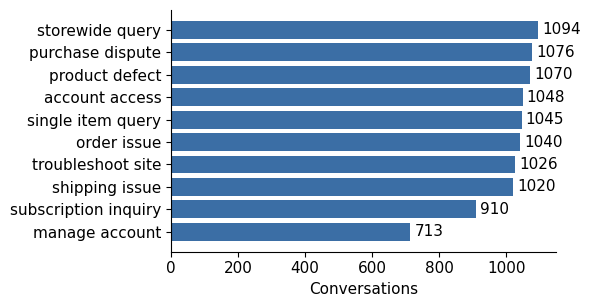

In [4]:
figure, ax = plt.subplots(figsize=(6, 3.2))
bars = ax.barh(flows.index.str.replace("_", " "), flows.values, color=COLOR)
ax.bar_label(bars, padding=3)
ax.invert_yaxis()
ax.set_xlabel("Conversations")
save(figure, "eda_flows")

## Subflow balance

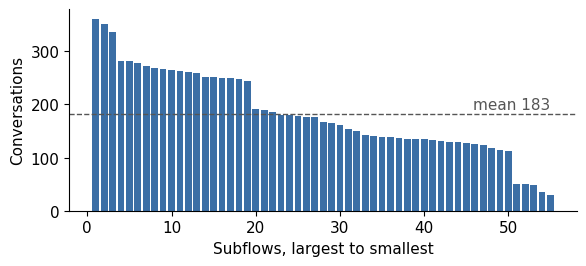

In [5]:
figure, ax = plt.subplots(figsize=(6, 2.8))
ax.bar(range(1, len(subflows) + 1), subflows.values, color=COLOR)
ax.axhline(subflows.mean(), color="#555555", linestyle="--", linewidth=1)
ax.text(len(subflows), subflows.mean() + 8, f"mean {subflows.mean():.0f}", ha="right", color="#555555")
ax.set_xlabel("Subflows, largest to smallest")
ax.set_ylabel("Conversations")
save(figure, "eda_subflows")

In [6]:
subflows.tail(5)

subflow
manage_change_name       51
manage_change_address    51
manage_change_phone      48
manage_payment_method    36
status_questions         30
Name: count, dtype: int64

## Conversation length

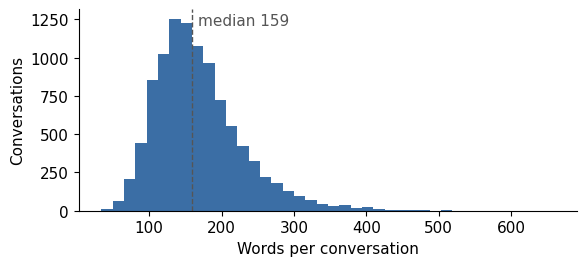

In [7]:
figure, ax = plt.subplots(figsize=(6, 2.8))
ax.hist(words, bins=40, color=COLOR)
ax.axvline(words.median(), color="#555555", linestyle="--", linewidth=1)
ax.text(words.median() + 8, ax.get_ylim()[1] * 0.92, f"median {words.median():.0f}", color="#555555")
ax.set_xlabel("Words per conversation")
ax.set_ylabel("Conversations")
save(figure, "eda_length")